In [1]:
# Question: How did revenue and the number of orders change month by month?
# Why? The SQL project had no time trend. A trend also helps explain the delivery results:
# if orders spike in November, late deliveries in that month are not surprising.
# Revenue means item price only (freight is not included), like in the SQL project.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Load the data
order_items = pd.read_csv('../csv_files/olist_order_items_dataset.csv')
orders = pd.read_csv('../csv_files/olist_orders_dataset.csv')

# Initial exploration of the dataset structure, shape, and missing values before any cleaning. 
# Lines commented out below were used for inspection and are kept for reference.

#orders.head()
#orders.tail()
#orders.shape
#orders.describe()
#orders.info()
#orders.isnull().sum()

print('orders:', orders.shape)
print('order_items:', order_items.shape)

# Data cleanup: Convert all relevant date/time columns to datetime format
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

# Missing values 
#print(orders.isnull().sum())

orders: (99441, 8)
order_items: (112650, 7)


In [2]:
# Add the purchase date and status to every item, and remove canceled and unavailable orders
sales = order_items.merge(orders[['order_id', 'order_purchase_timestamp', 'order_status']], on='order_id')
sales = sales[~sales['order_status'].isin(['canceled', 'unavailable'])].copy()

# Year and month in the form 2017-11
sales['year_month'] = sales['order_purchase_timestamp'].dt.to_period('M').astype(str)

In [3]:
# Revenue and number of different orders per month

monthly = sales.groupby('year_month').agg(
    revenue=('price', 'sum'),
    orders=('order_id', 'nunique')
)

monthly['avg_order_value'] = (monthly['revenue'] / monthly['orders']).round(2)

# Look at the first and last months before cutting them
#print(monthly.head(4))
#print(monthly.tail(4))

In [4]:
# The first and last months are incomplete, which would look like a collapse in the chart.
# Keep only the full months.
monthly = monthly.loc['2017-01':'2018-08']

peak_month = monthly['revenue'].idxmax()

print('Peak revenue month:', peak_month)
print('Revenue in that month:', monthly.loc[peak_month, 'revenue'])
print('Average order value:', monthly.loc[peak_month, 'avg_order_value'])

# Month-over-month growth in percent
growth = monthly['revenue'].pct_change() * 100
#print(growth.round(2))

Peak revenue month: 2017-11
Revenue in that month: 1003862.14
Average order value: 135.27


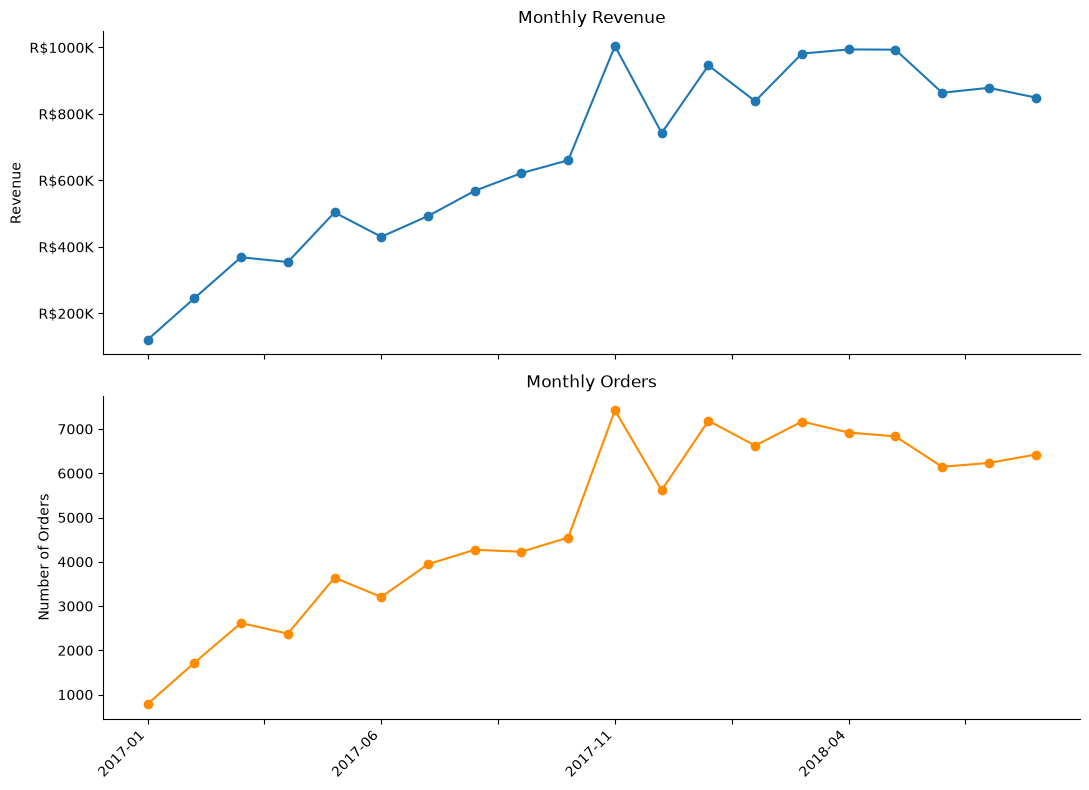

In [5]:
# Line charts: revenue and orders per month

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

monthly['revenue'].plot(ax=ax[0], marker='o')

ax[0].yaxis.set_major_formatter(FuncFormatter(lambda y, pos: f'R${int(y / 1000)}K'))
ax[0].set_title('Monthly Revenue')
ax[0].set_ylabel('Revenue')
    
monthly['orders'].plot(ax=ax[1], marker='o', color='darkorange')
ax[1].set_title('Monthly Orders')
ax[1].set_ylabel('Number of Orders')
ax[1].set_xlabel('')

plt.xticks(rotation=45, ha='right')
sns.despine()
fig.tight_layout()
plt.savefig('images/revenue_over_time.png', dpi=150, bbox_inches='tight')
plt.show()